<a href="https://colab.research.google.com/github/jovi1214/nurse-burnout-nlp-analysis/blob/main/nurse_burnout_nlp_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Final Project: Analyzing Nurse Burnout Through Language Patterns in Online Discussions

###Johana Villanueva

**BACKGROUND**

Nurse burnout is a major issue in healthcare, affecting not only the well-being of registered nurses but also patient outcomes and overall healthcare system performance. High levels of stress, emotional exhaustion, and staffing shortages have been widely documented, especially following COVID-19.

Traditional research on burnout often relies on surveys or structured data. However, nurses frequently share their experiences in more candid and unfiltered ways through online platforms. These discussions provide rich, real-world insight into burnout that may not be captured in formal studies.

**RESEARCH QUESTION**

Can natural language processing (NLP) be used to identify common themes and emotional patterns in discussions about nurse burnout?

In [ ]:
import pandas as pd

kaggle_df = pd.read_excel("Kaggle Nurse Burnout.xlsx")
reddit_df = pd.read_csv("Reddit Nurse Burnout.csv")

kaggle_df.head(), reddit_df.head(), statista_df.head()

(   Participant_ID  Age  Gender  Years_of_Experience  \
 0               1   30  Female                    5   
 1               2   35    Male                    8   
 2               3   28  Female                    3   
 3               4   40    Male                   12   
 4               5   32  Female                    6   
 
    Maslach_Burnout_Score_Pre  Maslach_Burnout_Score_Post  \
 0                         65                          45   
 1                         72                          50   
 2                         60                          40   
 3                         75                          48   
 4                         68                          42   
 
    Maslach_Burnout_Score_FollowUp  
 0                              40  
 1                              42  
 2                              38  
 3                              40  
 4                              36  ,
    source       subreddit                                            t

In [ ]:
#cleaning kaggle dataset

kaggle_clean = kaggle_df.copy()
kaggle_clean = kaggle_clean.dropna(how="all")
kaggle_clean = kaggle_clean.dropna(axis=1, how="all")
kaggle_clean = kaggle_clean.reset_index(drop=True)

print("Kaggle shape before:", kaggle_df.shape)
print("Kaggle shape after:", kaggle_clean.shape)


display(kaggle_clean.head())

Kaggle shape before: (50, 7)
Kaggle shape after: (50, 7)


,Participant_ID,Age,Gender,Years_of_Experience,Maslach_Burnout_Score_Pre,Maslach_Burnout_Score_Post,Maslach_Burnout_Score_FollowUp
0,1,30,Female,5,65,45,40
1,2,35,Male,8,72,50,42
2,3,28,Female,3,60,40,38
3,4,40,Male,12,75,48,40
4,5,32,Female,6,68,42,36


In [ ]:
#cleaning reddit dataset

reddit_df["combined_text"] = (
    reddit_df["title"] + " " + reddit_df["text"]
)

import re

def clean_text(t):
    t = str(t).lower()
    t = re.sub(r"http\S+", "", t)
    t = re.sub(r"[^a-z\s]", "", t)
    return t

reddit_df["clean"] = reddit_df["combined_text"].apply(clean_text)

In [ ]:
#measuring emotional tone of Reddit posts using VADER

import nltk
nltk.download('vader_lexicon')

from nltk.sentiment import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

reddit_df["sentiment"] = reddit_df["clean"].apply(
    lambda x: sia.polarity_scores(x)["compound"]
)

def label(x):
    if x >= 0.05:
        return "positive"
    elif x <= -0.05:
        return "negative"
    else:
        return "neutral"

reddit_df["label"] = reddit_df["sentiment"].apply(label)

reddit_df["label"].value_counts()

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


,count
label,
negative,10
positive,8


_Sentiment analysis of the Reddit dataset shows a slight predominance of negative sentiment, with 10 negative and 8 positive posts._

_The model shows a slight predominance of negative sentiment; however, a closer qualitative review suggests that the emotional tone is more consistently aligned with burnout-related distress._

In [ ]:
#identify recurring themes in Reddit posts

from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import LatentDirichletAllocation

#custom + default stopwords
custom_stopwords = [
    "im", "just", "like", "dont", "didnt", "ive", "youre", "theyre", "thats"
]

all_stopwords = list(ENGLISH_STOP_WORDS.union(custom_stopwords))

#vectorize text
vectorizer = CountVectorizer(
    stop_words=all_stopwords,
    min_df=2,
    max_df=0.8
)

X = vectorizer.fit_transform(reddit_df["clean"])

lda = LatentDirichletAllocation(n_components=2, random_state=42)
lda.fit(X)

#topics
words = vectorizer.get_feature_names_out()

for i, topic in enumerate(lda.components_):
    print(f"\nTopic {i}:")
    print([words[i] for i in topic.argsort()[-10:]])


Topic 0:
['think', 'time', 'patients', 'help', 'really', 'burnout', 'care', 'leaving', 'today', 'work']

Topic 1:
['know', 'day', 'patient', 'love', 'care', 'nursing', 'work', 'nurse', 'job', 'feel']


_Topic modeling identified two primary themes in the Reddit dataset._

_The first theme reflects burnout as a decision point, with terms such as “patients,” “help,” “burnout,” “leaving,” and “work.” This suggests posts where nurses are describing exhaustion in relation to patient care and possible movement away from the profession._

_The second theme reflects emotional and professional strain, with terms such as “nursing,” “feel,” “care,” and “nurse.” This suggests frustration and burnout tied to the nursing role itself._

In [ ]:
#summary stats for structured burnout indicators
kaggle_clean.describe()

,Participant_ID,Age,Years_of_Experience,Maslach_Burnout_Score_Pre,Maslach_Burnout_Score_Post,Maslach_Burnout_Score_FollowUp
count,50.00000,50.000000,50.000000,50.000000,50.000000,50.000000
mean,25.50000,33.780000,7.640000,69.840000,46.120000,40.340000
std,14.57738,4.621556,3.249867,6.453476,5.324721,3.772132
min,1.00000,26.000000,2.000000,57.000000,35.000000,32.000000
25%,13.25000,30.000000,5.000000,65.250000,43.000000,38.000000
50%,25.50000,33.500000,7.500000,70.000000,46.000000,40.000000
75%,37.75000,37.000000,10.000000,75.000000,50.000000,43.000000
max,50.00000,45.000000,15.000000,80.000000,55.000000,48.000000


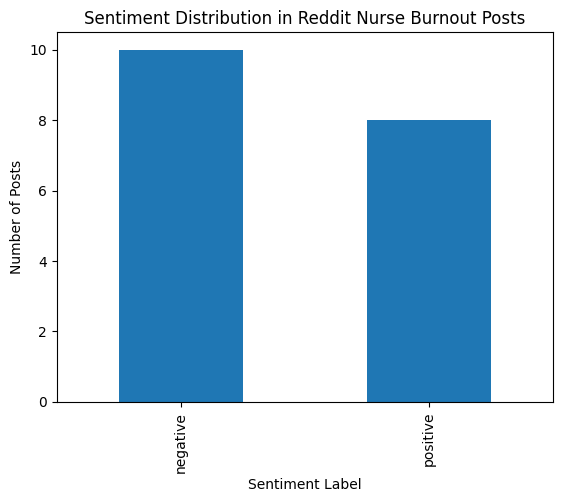

In [ ]:
import matplotlib.pyplot as plt

reddit_df["label"].value_counts().plot(kind="bar")
plt.title("Sentiment Distribution in Reddit Nurse Burnout Posts")
plt.xlabel("Sentiment Label")
plt.ylabel("Number of Posts")
plt.show()

**RESULTS**

Sentiment analysis of the Reddit dataset shows a slight predominance of negative sentiment, with 10 negative and 8 positive posts. This suggests that burnout-related discussions tend to reflect emotional distress, though there is variation in how nurses describe their experiences.

Topic modeling identified two primary themes in the Reddit dataset. The first theme reflects burnout as a decision point, with terms such as “patients,” “burnout,” “leaving,” and “work,” suggesting that nurses are expressing exhaustion in relation to patient care and considering leaving the profession. The second theme reflects emotional and professional strain, with terms such as “nursing,” “feel,” “care,” and “nurse,” indicating frustration tied to the role itself.

Structured data from the Kaggle dataset supports these findings, showing measurable burnout scores across participants, reinforcing that burnout is both subjectively expressed and quantitatively observable.

**DISCUSSION**

The results demonstrate that NLP techniques can effectively extract meaningful patterns from unstructured text data. Sentiment analysis provides a high-level understanding of emotional tone, while topic modeling reveals underlying drivers of burnout such as workload, patient interaction, and emotional fatigue.

By combining Reddit data with structured Kaggle data, this project highlights how qualitative and quantitative approaches can complement each other. While structured datasets measure burnout through predefined indicators, unstructured text captures real-time, lived experiences that may not be fully reflected in surveys.

**LIMITATIONS**

This analysis is based on a small, manually curated Reddit dataset, which may not be representative of the broader nursing population. Sentiment analysis using VADER may not fully capture nuanced emotions such as sarcasm or mixed sentiment. Additionally, topic modeling results are sensitive to preprocessing choices and dataset size. The Statista dataset was used only for contextual support and not included in the modeling process due to formatting limitations.

**CONCLUSION**

This project demonstrates that natural language processing can be used to analyze nurse burnout through language patterns in online discussions. The findings show that burnout is reflected both emotionally and thematically, with key drivers including workload, patient care demands, and emotional exhaustion. Integrating unstructured and structured data provides a more comprehensive understanding of burnout, suggesting that NLP can be a valuable tool for healthcare analytics.